Работа со звуком

In [1]:
srcML_School = 'D:\\MIREA\\DPO\\Learning\\ML_School'
# < 20 Гц - Инфразвук
# > 20 кГц - ультразвук (для нас не важен)

Работа с библиотекой pydub
(для yupiter надо ещё ffmpeg скачать)

In [2]:
from pydub import AudioSegment


src = srcML_School + '\\test.mp3'
dst = srcML_School + '\\test.wav'
sound = AudioSegment.from_mp3(src)
mid = int(len(sound) / 2)
print(mid)

1149


In [3]:
firstHalf = sound[:mid]
lastHalf = sound[mid:]
sound = lastHalf + firstHalf
sound.export(dst, format='wav')

<_io.BufferedRandom name='D:\\MIREA\\DPO\\Learning\\ML_School\\test.wav'>

In [4]:
from pydub.playback import play
# В Colab не работает

sound = AudioSegment.from_wav(dst)
play(sound)
# Не трогать, кака!!!!
# Для питона 3.12.5 и юпитера в VS Code умирает после выполнения (баг)

Прослушивание звука в IPython.display

Встроена в Jupyter, может работать с множеством форматов

In [5]:
import IPython.display as ipd

In [6]:
ipd.Audio(src)

In [7]:
ipd.Audio(dst)

Работа с библиотекой simpleaudio

In [8]:
import sys  
sys.path.append('D:\\MIREA\\DPO\\Learning')

# import sys
# import os
# sys.path.insert(0, os.path.abspath('Learning\\ML_School'))

In [9]:
import simpleaudio as sa
from ML_School.utils import byte_to_float


waveObj = sa.WaveObject.from_wave_file(dst)
playing1 = waveObj.play()
tmp = byte_to_float(waveObj.audio_data)
ipd.Audio(data=tmp, rate=2 * waveObj.sample_rate)

Создание простого звука в simpleaudio

In [10]:
import numpy as np


frequency = 440
fs = 44100 #Частота дискретизации
seconds = 3

t = np.linspace(0, seconds, seconds * fs, False)

note = np.sin(frequency * t * 2 * np.pi)
audio = note * (2 ** 15 - 1) / np.max(np.abs(note))
audio = audio.astype(np.int16)

playObg = sa.play_buffer(audio, 1, 2, fs)

In [11]:
playObg.stop()

Создание простого звука в IPython

In [12]:
frequency = 440
fs = 44100
seconds = 3

t = np.linspace(0, seconds, seconds * fs, False)

note = np.sin(frequency * 2 * np.pi * t)
audio = 2. * (note - np.min(note)) / np.ptp(note) - 1
ipd.Audio(audio, rate=fs)

In [13]:
# Получение звука с микрофона в браузере
# from IPython.core.display import display_html, HTML, Javascript Фигня от gpt
from IPython.display import HTML, Audio, Javascript # библиотеки для работы с HTML и воспроизведения звука
# from google.colab.output import eval_js # для выполнения Javascript
from base64 import b64decode # для конвертирования звука в подходящий формат
import numpy as np
from scipy.io.wavfile import read as wav_read # для чтения wav файлов
import io # ввод\вывод
import ffmpeg # для работы с mpeg

AUDIO_HTML = '''
<script>
var my_div = document.createElement("DIV");
var my_p = document.createElement("P");
var my_btn = document.createElement("BUTTON"); // кнопка начала записи
var t = document.createTextNode("Press to start recording"); // текст кнопки начала записи

my_btn.appendChild(t);
my_div.appendChild(my_btn);
document.body.appendChild(my_div);

var base64data = 0;
var reader;
var recorder, gumStream;
var recordButton = my_btn;

// функция для создания потока аудио
var handleSuccess = function(stream) {
  gumStream = stream;
  var options = {
    //bitsPerSecond: 8000, /хром игнорирует, всегда 48к
    mimeType : 'audio/webm;codecs=opus'
    //mimeType : 'audio/webm;codecs=pcm'
  };

  recorder = new MediaRecorder(stream); // интерфейс для записи
  recorder.ondataavailable = function(e) {
    var url = URL.createObjectURL(e.data);
    var preview = document.createElement('audio');
    preview.controls = true;
    preview.src = url;
    document.body.appendChild(preview);

    reader = new FileReader();
    reader.readAsDataURL(e.data);
    reader.onloadend = function() {
      base64data = reader.result;
      //console.log("Inside FileReader:" + base64data);
    }
  };
  recorder.start(); //начинаем запись
  };

recordButton.innerText = "Recording... press to stop"; // меняем текст кнопки

navigator.mediaDevices.getUserMedia({audio: true}).then(handleSuccess);

// включение\выключение записи
function toggleRecording() {
  if (recorder && recorder.state == "recording") {
      recorder.stop(); // останавливаем запись
      gumStream.getAudioTracks()[0].stop();
      recordButton.innerText = "Saving the recording... pls wait!" // меняем текст кнопки
  }
}

// https://stackoverflow.com/a/951057

// пауза
function sleep(ms) {
  return new Promise(resolve => setTimeout(resolve, ms));
}

// эти данные будут отправляться в Python
var data = new Promise(resolve=>{
recordButton.onclick = ()=>{
toggleRecording()

sleep(2000).then(() => {
  // ждем 2000ms доступности данных...

  resolve(base64data.toString())

});

}
});

</script>
'''

# Функция получения записи

# def get_audio():
#   display(HTML(AUDIO_HTML)) # Создаём HTML
#   data = Javascript("data") # Выполняем
#   binary = b64decode(data.split(',')[1])

#   # handilng
#   process = (ffmpeg
#     .input('pipe:0')
#     .output('pipe:1', format='wav')
#     .run_async(pipe_stdin=True, pipe_stdout=True, pipe_stderr=True, quiet=True, overwrite_output=True)
#     )
#   output, err = process.communicate(input=binary)
#   # байты надо расставить в правильном порядке для Wav
#   riff_chunk_size = len(output) - 8
#   # Break up the chunk size into four bytes, held in b.
#   q = riff_chunk_size
#   b = []
#   for i in range(4):
#     q, r = divmod(q, 256)
#     b.append(r)

#   # Replace bytes 4:8 in proc.stdout with the actual size of the RIFF chunk.
#   riff = output[:4] + bytes(b) + output[8:]

#   # читаем в Wav из буфера
#   sr, audio = wav_read(io.BytesIO(riff))
#   # sr - частота дискретизации
#   # audio - звук в формате Wav.
#   return audio, sr

In [14]:
# audio, sr = get_audio()

Запись звука soundevice

In [15]:
!pip install sounddevice

In [16]:
import sounddevice as sd
from scipy.io.wavfile import write

In [17]:
sd.query_devices()

   0 Переназначение звуковых устр. - Input, MME (2 in, 0 out)
>  1 Набор микрофонов (Realtek(R) Au, MME (2 in, 0 out)
   2 Головной телефон (realme Buds A, MME (1 in, 0 out)
   3 Переназначение звуковых устр. - Output, MME (0 in, 2 out)
<  4 Наушники (realme Buds Air6), MME (0 in, 2 out)
   5 Динамики (Realtek(R) Audio), MME (0 in, 8 out)
   6 Первичный драйвер записи звука, Windows DirectSound (2 in, 0 out)
   7 Набор микрофонов (Realtek(R) Audio), Windows DirectSound (2 in, 0 out)
   8 Головной телефон (realme Buds Air6), Windows DirectSound (1 in, 0 out)
   9 Первичный звуковой драйвер, Windows DirectSound (0 in, 2 out)
  10 Наушники (realme Buds Air6), Windows DirectSound (0 in, 2 out)
  11 Динамики (Realtek(R) Audio), Windows DirectSound (0 in, 8 out)
  12 Наушники (realme Buds Air6), Windows WASAPI (0 in, 2 out)
  13 Динамики (Realtek(R) Audio), Windows WASAPI (0 in, 2 out)
  14 Головной телефон (realme Buds Air6), Windows WASAPI (1 in, 0 out)
  15 Набор микрофонов (Realtek(R) Au

In [18]:
fs = 44100
seconds = 5
myRecording = sd.rec(int(seconds * fs), samplerate=fs, channels=1, device=1)
sd.wait()
write(srcML_School + '\\output.wav', fs, myRecording)
sd.play(myRecording, fs*2)

In [19]:
import IPython.display as ipd

ipd.Audio(srcML_School + '\\output.wav')

Библиотека pyaudio. Воспроизведение

In [20]:
!apt install libasound2-dev portaudio19-dev libportaudio2 libportaudiocpp0 ffmpeg
!pip install pyaudio

"apt" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [21]:
import pyaudio
import wave

chunk = 1024

wf = wave.open(dst, 'rb')

p = pyaudio.PyAudio()

stream = p.open(format=p.get_format_from_width(wf.getsampwidth()),
                channels=wf.getnchannels(),
                rate=wf.getframerate(),
                output=True)

data = wf.readframes(chunk)

while data != b'':
    stream.write(data)
    data = wf.readframes(chunk)

stream.close()
p.terminate()

Запись звука с pyaudio

In [22]:
chunk = 1024
sampleFormat = pyaudio.paInt16
channels = 1
fs = 44100
seconds = 3
inputDevicesIndex = 1
filename = 'D:/MIREA/DPO/Learning/ML_School/output.wav'

p = pyaudio.PyAudio()

print('Recording')

stream = p.open(format=sampleFormat,
                channels=channels,
                rate=fs,
                frames_per_buffer=chunk,
                input=True,
                input_device_index=inputDevicesIndex)

frames = []

for i in range(0, int(fs / chunk * seconds)):
    data = stream.read(chunk)
    data1 = bytearray(data)
    frames.append(data1)

stream.stop_stream()
stream.close()
p.terminate()

print('Finish recording')

wf = wave.open(filename, 'wb')
wf.setnchannels(channels)
wf.setsampwidth(p.get_sample_size(sampleFormat))
wf.setframerate(fs)
wf.writeframes(b''.join(frames))
wf.close()

Recording
Finish recording


In [23]:
ipd.Audio(filename)

In [24]:
# p.get_device_info_by_index(1) Ошибка(

Визуализация

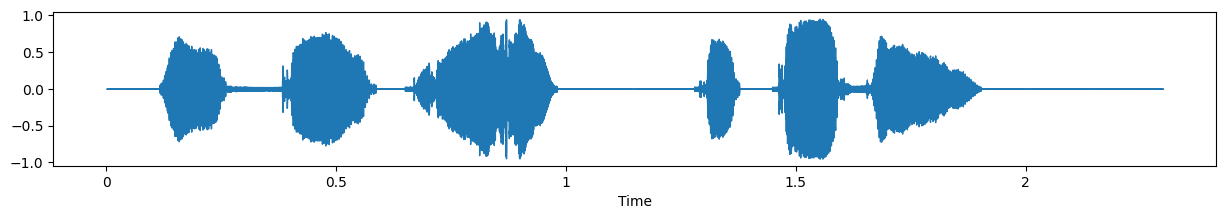

In [25]:
import matplotlib.pyplot as plt
import librosa

filename1 = srcML_School + '\\test.wav'

plt.figure(figsize=(15, 2))

data1, sample_rate1 =  librosa.load(filename1,
                                    sr=44100,
                                    mono=True,
                                    offset=0.0,
                                    duration=200,
                                    res_type='scipy')

librosa.display.waveshow(data1, sr=sample_rate1)

ipd.Audio(data1, rate=sample_rate1)

In [26]:
print(data1)
print(len(data1))
print(sample_rate1)

[0.0000000e+00 0.0000000e+00 0.0000000e+00 ... 3.0517578e-05 0.0000000e+00
 0.0000000e+00]
101385
44100


Отрисовка через matplotlib.pyplot

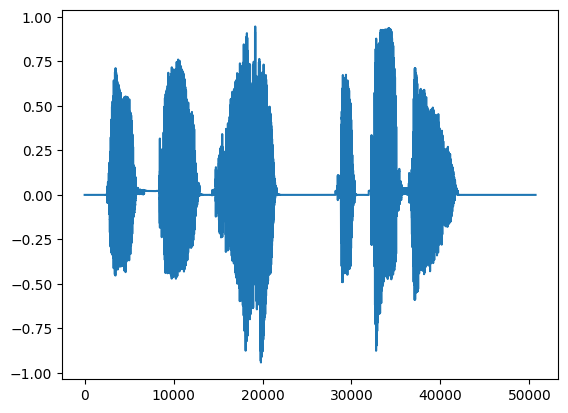

In [27]:
signal, sr = librosa.load(filename1)

plt.plot(signal)

Добавим шум (сосед, машины...)

Обычно мешает, но иногда помогает в обработке звука

Некоторые нейро сети используют шум

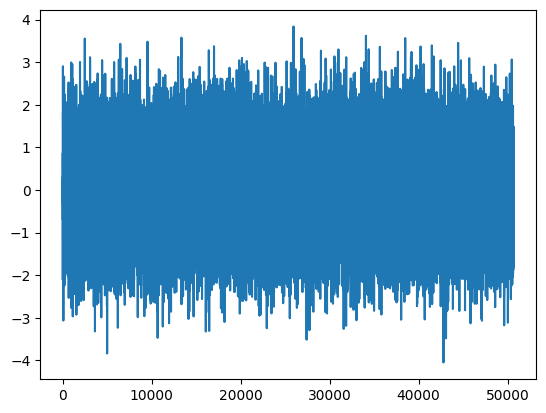

In [28]:
import numpy as np


h = .9
noise = np.random.normal(0, h, signal.shape[0])
signal_noise = signal + noise
plt.plot(signal_noise)
ipd.Audio(signal_noise, rate=sr)

Частотное представдление и спектр

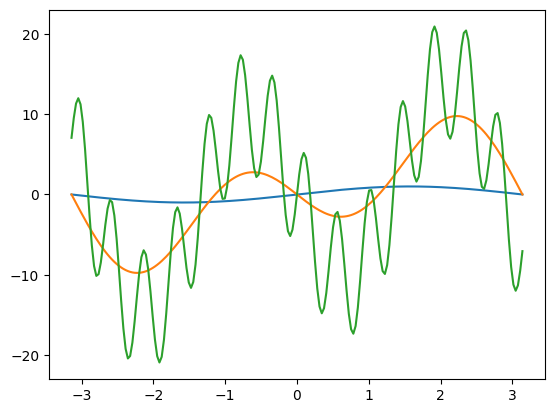

In [29]:
x = np.linspace(-np.pi, np.pi, 201)
y1 = np.sin(x)
y2 = 5 * np.sin(x) - 6 * np.sin(2 * x)
y3 = 3 * np.sin(x) - 12 * np.sin(2.2 * x) + 7.6 * np.sin(14 * x)
plt.plot(x, y1, x, y2, x, y3)

Храним только амплитуду и частоту для переодической функции

Asin(wt)

Для изменяемой можно хранить массивом

(1025, 100)


Text(0.5, 1.0, 'Спектр с шумом')

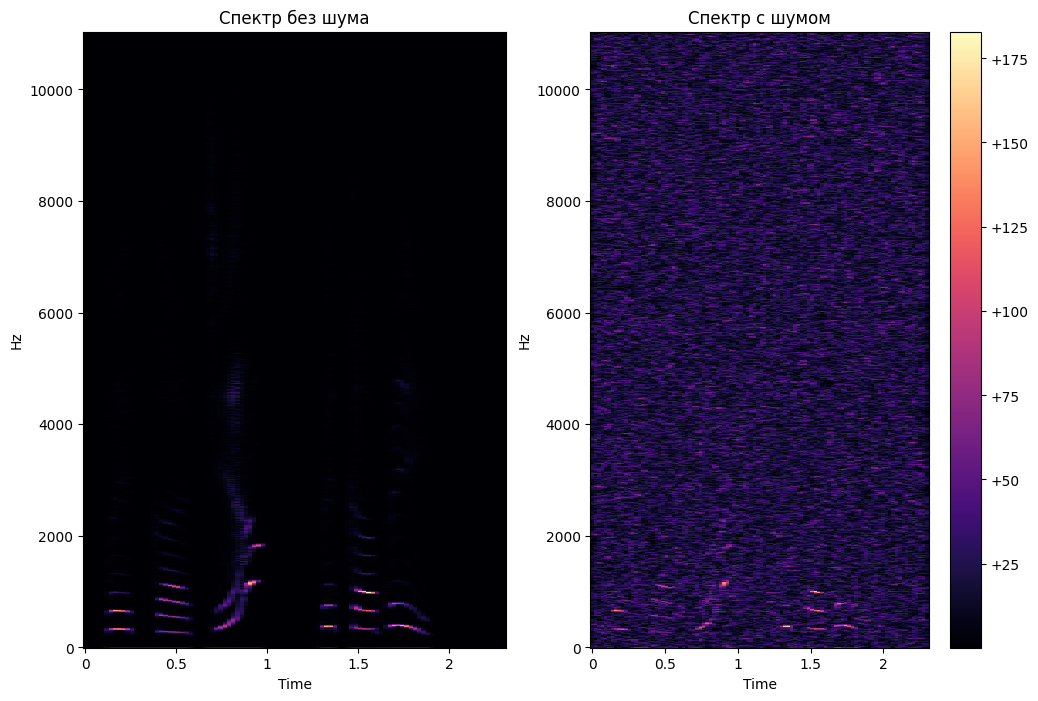

In [30]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
D_compl = librosa.stft(signal)
D = np.abs(D_compl)
print(D.shape)
librosa.display.specshow(D, 
                         x_axis='time',
                         y_axis='linear')
plt.title('Спектр без шума')

plt.subplot(1, 2, 2)
D_compl = librosa.stft(signal_noise)
D = np.abs(D_compl)
librosa.display.specshow(D,
                         x_axis='time',
                         y_axis='linear')
plt.colorbar(format='%+2.0f')
plt.title('Спектр с шумом')

C:\Users\nuyki\AppData\Local\Temp\ipykernel_20664\3931999321.py:6: UserWarning:

Trying to display complex-valued input. Showing magnitude instead.



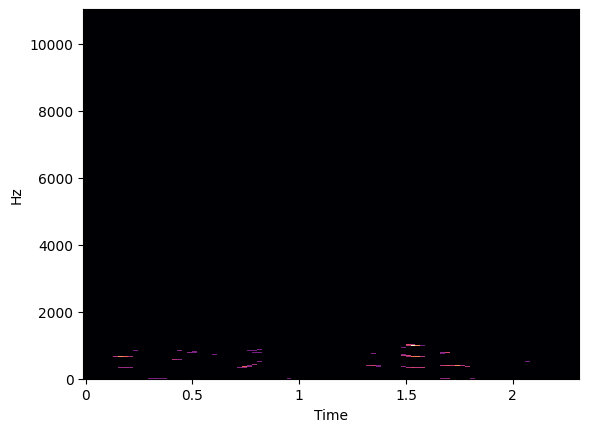

In [31]:
threshold = 60
freq_max = 100
D_compl1 = D_compl.copy()
D_compl1[np.where(D < threshold)] = 0
D_compl1[freq_max:, :] = 0
librosa.display.specshow(D_compl1,
                         x_axis='time',
                         y_axis='linear')

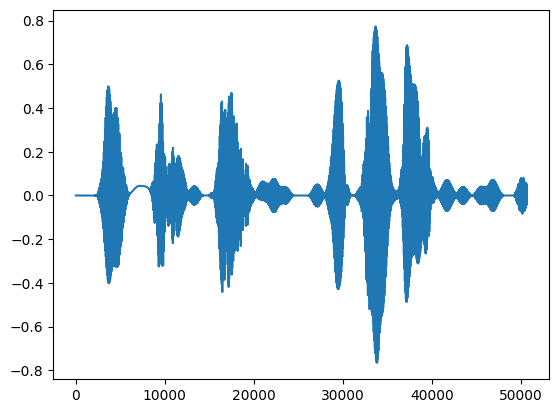

In [32]:
signal_reconstructed = librosa.istft(D_compl1)
plt.plot(signal_reconstructed)
ipd.Audio(signal_reconstructed, rate =sr)

Дополнительное задание

1. Записать свой голос
2. Зашумить его
3. Перевести его в спектр
4. Создать денойз продвинутым способом

In [33]:
# Запись голоса
import sounddevice as sd
import pyaudio
import wave
import IPython.display as ipd
from scipy.io.wavfile import write

In [34]:
sd.query_devices()

   0 Переназначение звуковых устр. - Input, MME (2 in, 0 out)
>  1 Набор микрофонов (Realtek(R) Au, MME (2 in, 0 out)
   2 Головной телефон (realme Buds A, MME (1 in, 0 out)
   3 Переназначение звуковых устр. - Output, MME (0 in, 2 out)
<  4 Наушники (realme Buds Air6), MME (0 in, 2 out)
   5 Динамики (Realtek(R) Audio), MME (0 in, 8 out)
   6 Первичный драйвер записи звука, Windows DirectSound (2 in, 0 out)
   7 Набор микрофонов (Realtek(R) Audio), Windows DirectSound (2 in, 0 out)
   8 Головной телефон (realme Buds Air6), Windows DirectSound (1 in, 0 out)
   9 Первичный звуковой драйвер, Windows DirectSound (0 in, 2 out)
  10 Наушники (realme Buds Air6), Windows DirectSound (0 in, 2 out)
  11 Динамики (Realtek(R) Audio), Windows DirectSound (0 in, 8 out)
  12 Наушники (realme Buds Air6), Windows WASAPI (0 in, 2 out)
  13 Динамики (Realtek(R) Audio), Windows WASAPI (0 in, 2 out)
  14 Головной телефон (realme Buds Air6), Windows WASAPI (1 in, 0 out)
  15 Набор микрофонов (Realtek(R) Au

In [35]:
# Есть микрофоны Realtek 2 in
# Запись в определённый промежуток времени

destination_file = 'D:\\MIREA\\DPO\\Learning\\Practic1_5\\voiceFromMicro'
fs = 44100
seconds = 5
channels = 2
inp_device = 1

recoding_voice = sd.rec(int(fs * seconds), fs, channels, device=inp_device)
sd.wait()
write(destination_file, fs, recoding_voice)

In [36]:
sd.play(recoding_voice, fs)

In [37]:
!pip install keyboard

In [38]:
# Запись с кнопкой
import keyboard as kb

chunk = 1024
sample_format = pyaudio.paInt24 # 3 байта на выборку (6 на кадр: 2*3)
channels = 2
fs = 44100
index_input_device = 1
destination_file2 = 'D:\\MIREA\\DPO\\Learning\\Practic1_5\\voiceFromMicro2.wav'

p = pyaudio.PyAudio()

print('Запись!')

stream = p.open(rate=fs, channels=channels, format=sample_format,
                input_device_index=index_input_device, input=True,
                frames_per_buffer=chunk)


frames = []

while True:
    if kb.is_pressed("s"):
        break
    data = stream.read(chunk)
    data1 = bytearray(data)
    frames.append(data1)

stream.stop_stream()
stream.close()
p.terminate()

print('Конец записи!')

wf = wave.open(destination_file2, 'wb')
wf.setnchannels(channels)
wf.setsampwidth(p.get_sample_size(sample_format))
wf.setframerate(fs)
wf.writeframes(b''.join(frames))
wf.close()

Запись!
Конец записи!


In [39]:
ipd.Audio(destination_file2)

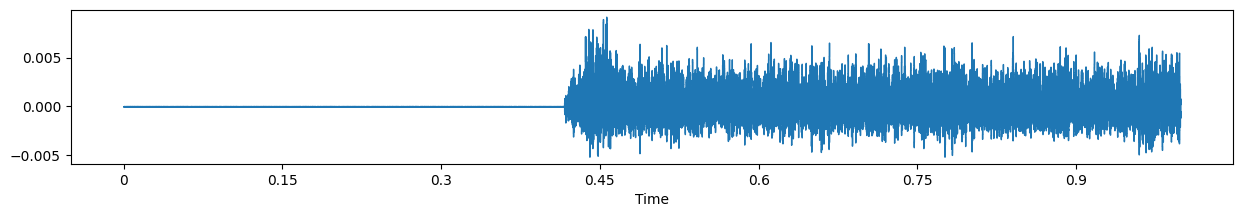

In [40]:
plt.figure(figsize=(15, 2))

voice, sample_rate = librosa.load(destination_file2,
                                  sr=fs,
                                  mono=False,
                                  offset=0.0,
                                  duration=5,
                                  res_type='scipy')

librosa.display.waveshow(voice, sr=sample_rate)


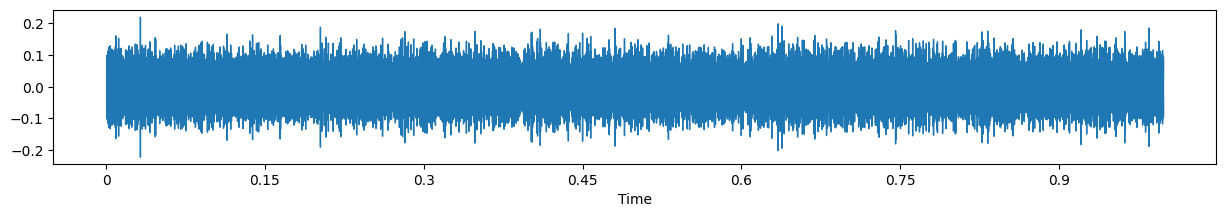

In [41]:
# Зашумим

plt.figure(figsize=(15, 2))

voice, sample_rate = librosa.load(destination_file2)
noise_ratio = .05
noise = np.random.normal(0, noise_ratio, voice.shape[0])
voice_noise = voice + noise

librosa.display.waveshow(voice_noise, sr=sample_rate)

ipd.Audio(voice_noise, rate=sample_rate)

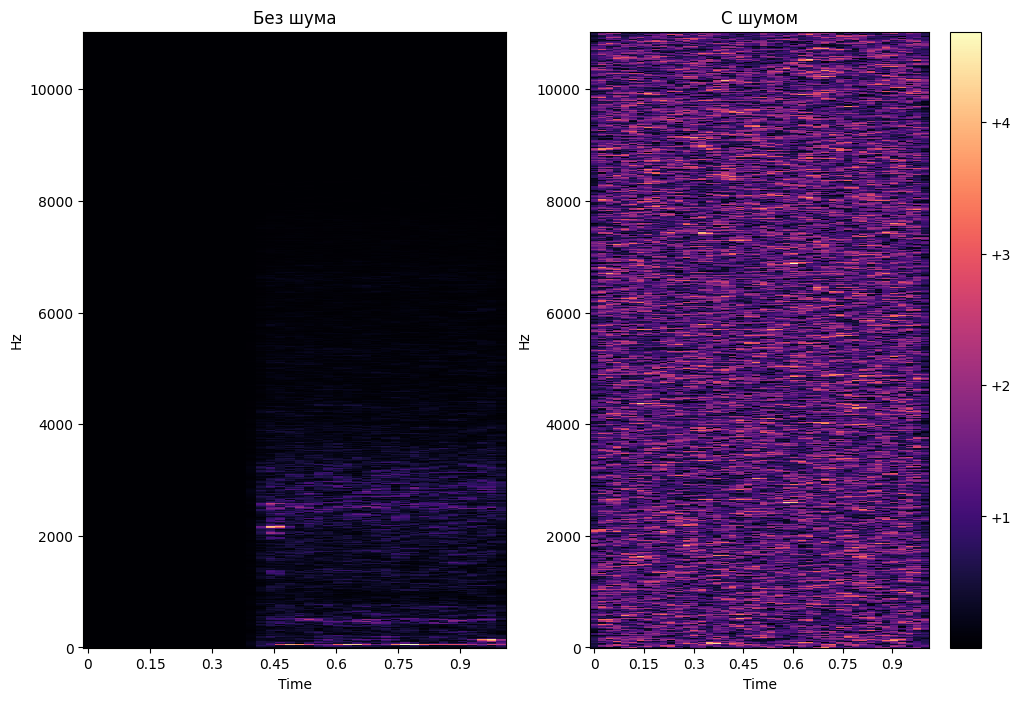

In [42]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
D_compl = librosa.stft(voice)
D = np.abs(D_compl)
librosa.display.specshow(D,
                         x_axis='time',
                         y_axis='linear')
plt.title('Без шума')

plt.subplot(1, 2, 2)
D_compl = librosa.stft(voice_noise)
D = np.abs(D_compl)
librosa.display.specshow(D,
                         x_axis='time',
                         y_axis='linear')
plt.colorbar(format='%+2.0f')
plt.title('С шумом')

plt.show()

C:\Users\nuyki\AppData\Local\Temp\ipykernel_20664\3623217415.py:8: UserWarning:

Trying to display complex-valued input. Showing magnitude instead.



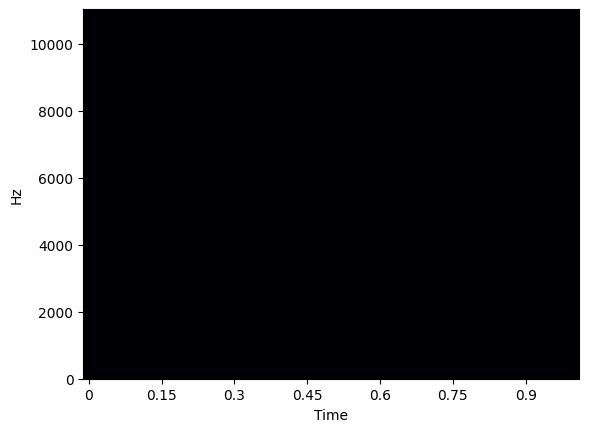

In [43]:
# Очищаем стандартным способом

threshold = 4
freq_max = 50
D_compl1 = D_compl.copy()
D_compl1[np.where(D < threshold)] = 0
D_compl1[freq_max:, : ] = 0
librosa.display.specshow(D_compl1,
                         x_axis='time',
                         y_axis='linear')


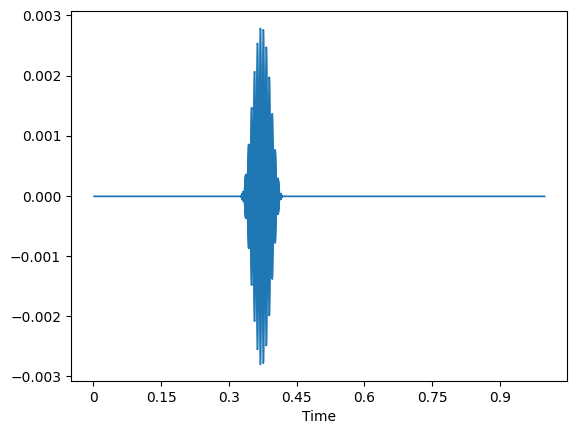

In [44]:
signal_reconstructed = librosa.istft(D_compl1)
librosa.display.waveshow(signal_reconstructed, sr=sample_rate)
ipd.Audio(signal_reconstructed, rate=sample_rate)

In [45]:
# Слабый звук трудно восстановим(

Анализ Фурье для фильтрации с предположением, что шум перекрывает сигналы во временной области, но не перекрывается в частотной области

In [ ]:
voice, sr = librosa.load(dst)

22050


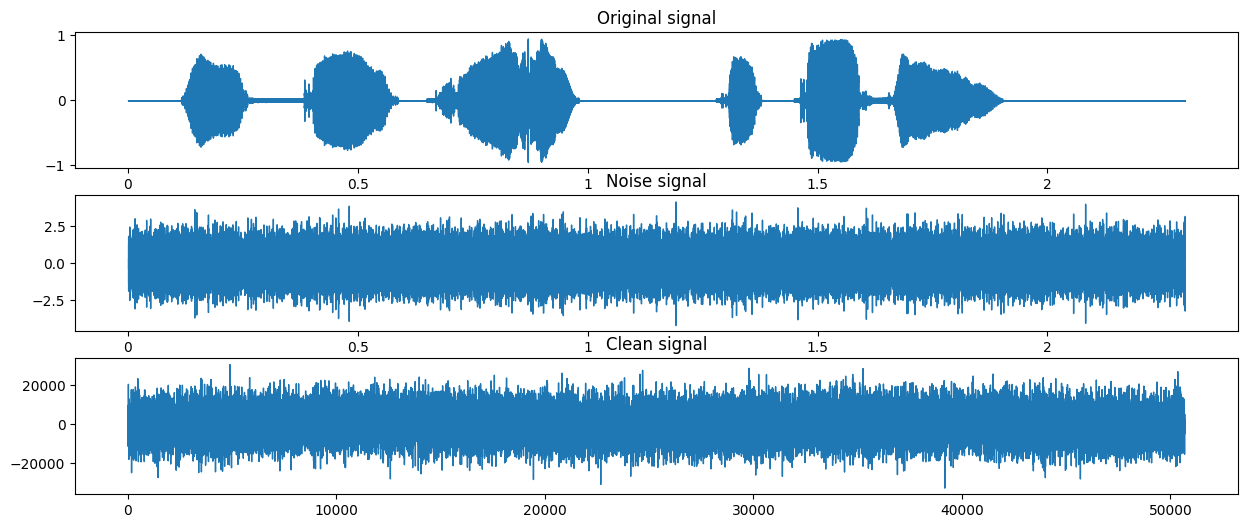

In [132]:
import pandas


plt.figure(figsize=(15, 6))

noise_ratio = .9
noise = np.random.normal(0, noise_ratio, voice.shape[0])
voice_with_noise = voice + noise
plt.subplot(3, 1, 1)
plt.title('Original signal')
librosa.display.waveshow(voice)

plt.subplot(3, 1, 2)
plt.title('Noise signal')
librosa.display.waveshow(voice_with_noise)

plt.subplot(3, 1, 3)
plt.title('Clean signal')
# Cleaning

min_signal, max_signal = voice_with_noise.min(), voice_with_noise.max()

# Быстрое преобразование Фурье
n = voice.shape[0]
fhat = np.fft.fft(voice_with_noise, n)
psd = fhat * np.conj(fhat) / n
freq = (1 / (noise_ratio * n)) * np.arange(n)
idxs_half = np.arange(1, np.floor(n / 2), dtype=np.int32)
threshold = 4.5
psd_idxs = psd > threshold
psd_clean = psd * psd_idxs
fhat_clean = psd_idxs * fhat

voice_filtered = np.fft.ifft(fhat_clean)

voice_filtered = np.real(voice_filtered) 
voice_filtered = voice_filtered / np.max(np.abs(voice_filtered)) 

voice_filtered = np.int16(voice_filtered * 32767)  # Умножаем на максимум для int16

write(srcML_School + '\\filterVoice.wav', sr, voice_filtered)
write(srcML_School + '\\noiseVoice.wav', sr, voice_with_noise)
plt.plot(np.arange(0, n), voice_filtered, lw=1, label='Clean Signal')
# librosa.display.waveshow(voice_filtered)

In [140]:
ipd.Audio(voice_with_noise, rate=sr)

Спектральное вычитание

In [147]:
audio, sr = librosa.load(srcML_School + '\\noiseVoice.wav')
stft = librosa.stft(audio)
magnitude = np.abs(stft)
phase = np.angle(stft)
beta = 2 # 1-3 обычно
noise_profile = None
# Оценка шума (первые 50 мс считаются шумом)
if noise_profile is None:
    noise_frames = stft[:, :int(0.05 * sr / (len(audio) / len(stft[0])))]
    noise_profile = np.mean(np.abs(noise_frames), axis=1, keepdims=True)
    
magnitude_clean = np.maximum(magnitude - beta * noise_profile, 0)
    
clean_stft = magnitude_clean * np.exp(1j * phase)
audio_clean = librosa.istft(clean_stft)

ipd.Audio(audio_clean, rate=sr*2)

Адаптивный фильтр Винера

In [159]:
noise_power=2000
snr_estimate=10
stft = librosa.stft(audio)
magnitude = np.abs(stft)
phase = np.angle(stft)
    
if noise_power is None:
    # Автоматическая оценка мощности шума
    noise_frames = stft[:, :int(0.05 * sr / (len(audio) / len(stft[0])))]
    noise_power = np.mean(np.abs(noise_frames)**2, axis=1, keepdims=True)
    
# Расчет коэффициентов Винера
signal_power = np.maximum(magnitude ** 2 - noise_power, 0)
wiener_coeff = signal_power / (signal_power + noise_power)
    
# Применение фильтра
clean_stft = wiener_coeff * stft
audio_clean = librosa.istft(clean_stft)
ipd.Audio(audio_clean, rate=sr*2)

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 42934 (\N{LATIN CAPITAL LETTER OMEGA}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 42934 (\N{LATIN CAPITAL LETTER OMEGA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


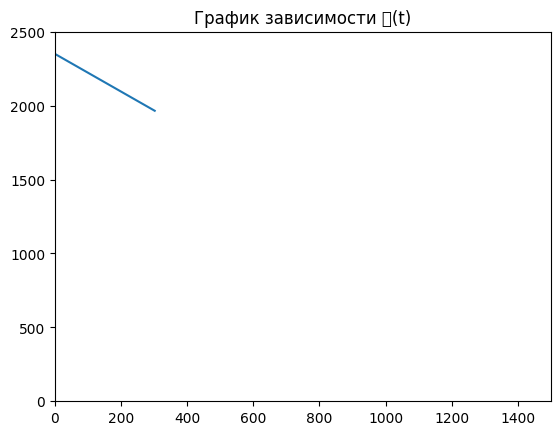

In [ ]:
import matplotlib.pyplot as plt
# import numpy as np


omega_work = 1965
moment_work = 302
max_omega_work = 2350

plt.title('График зависимости Ꞷ(t)')
plt.xlim(0, 1500)
plt.ylim(0, 2500)
plt.plot([0, moment_work], [max_omega_work, omega_work])


